<a href="https://colab.research.google.com/github/shriya-dev-ui/lab1aiml/blob/main/Stroke_SMOTE_Classifier_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Exercise: Handling Class Imbalance with SMOTE on the Stroke Dataset
**Course:** B.Tech CSE (AI & ML)

**Objective:** Balance the processed Stroke dataset with **SMOTE**, train six classifiers (Logistic Regression, KNN, Random Forest, Gradient Boosting, SVM, ANN), and compare them with the same models trained on the original imbalanced data using Precision, Recall, F1-Score, Accuracy, AUC-ROC and the Confusion Matrix. Finally, identify the **Top 3 models**.

The classifier set follows the earlier lab (Logistic Regression, Random Forest, Gradient Boosting, SVM, ANN as `MLPClassifier`) with **KNN** added as the sixth model.

**Workflow:** upload data → inspect imbalance → split/scale → imbalanced baseline → SMOTE (training set only) → balanced models → confusion matrices / ROC → comparison tables → Top 3.

## 1. Import Libraries

In [3]:
!pip install -q imbalanced-learn

import io, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the Dataset (manual entry)
Run the cell and select your processed Stroke dataset (CSV or Excel).

In [4]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
print("Uploaded:", file_name)

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Shape:", df.shape)
display(df.head())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Uploaded: stroke_processed_5k.csv
Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


Missing values: 0 | Duplicate rows: 0

Class counts:
 stroke
0    4861
1     249
Name: count, dtype: int64

Percentage:
 stroke
0    95.13
1     4.87
Name: count, dtype: float64

Imbalance ratio = 19.5 : 1


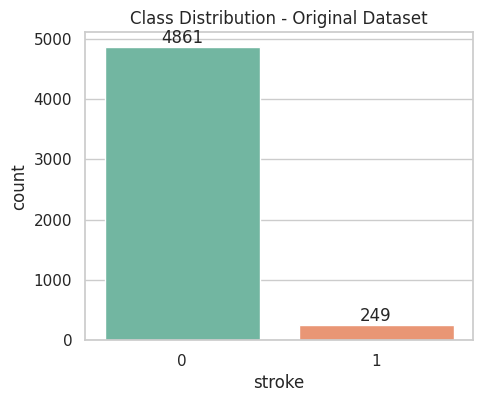

In [5]:
TARGET = "stroke"      # <-- change if your target column has a different name
TEST_SIZE = 0.20

match = [c for c in df.columns if c.lower() == TARGET.lower()]
assert match, f"Target column '{TARGET}' not found. Columns: {list(df.columns)}"
TARGET = match[0]

print("Missing values:", int(df.isnull().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
counts = df[TARGET].value_counts().sort_index()
print("\nClass counts:\n", counts)
print("\nPercentage:\n", (counts / len(df) * 100).round(2))
print(f"\nImbalance ratio = {counts.max() / counts.min():.1f} : 1")

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=TARGET, data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Class Distribution - Original Dataset")
plt.show()

## 3. Prepare Features, Split and Scale
The dataset is already processed (numeric), so only light safety checks are applied. A **stratified** split keeps the stroke ratio the same in train and test. The scaler is fitted on the training data only.

In [6]:
data = df.copy()
for c in data.columns:
    if c.lower() in ("id", "unnamed: 0", "index"):
        data.drop(columns=c, inplace=True)

# Safety net: encode any leftover text columns / fill missing values
cat_cols = data.drop(columns=TARGET).select_dtypes(include="object").columns.tolist()
if cat_cols:
    print("Encoding leftover categorical columns:", cat_cols)
    data = pd.get_dummies(data, columns=cat_cols, drop_first=True)
data = data.fillna(data.median(numeric_only=True))

X = data.drop(columns=TARGET).astype(float)
y = data[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Train:", X_train_sc.shape, dict(y_train.value_counts().sort_index()))
print("Test :", X_test_sc.shape, dict(y_test.value_counts().sort_index()))

Train: (4088, 10) {0: np.int64(3889), 1: np.int64(199)}
Test : (1022, 10) {0: np.int64(972), 1: np.int64(50)}


## 4. Model Definitions and Evaluation Helpers
All six models are scikit-learn estimators. **No early stopping** is used for the ANN (`MLPClassifier`, fixed training length).

In [7]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05,
                                                        max_depth=2, random_state=RANDOM_STATE),
        "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        "ANN": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                             alpha=0.0005, learning_rate_init=0.001, max_iter=300,
                             early_stopping=False, random_state=RANDOM_STATE),
    }

def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC-ROC": roc_auc_score(y_true, y_prob),
    }

def plot_confusion_matrices(preds, y_true, title, cmap="Blues"):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (name, pred) in zip(axes.ravel(), preds.items()):
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                    xticklabels=["No Stroke", "Stroke"], yticklabels=["No Stroke", "Stroke"])
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(title, fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

def confusion_table(preds, y_true):
    rows = {}
    for name, pred in preds.items():
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows[name] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp}
    t = pd.DataFrame(rows).T
    t["All 4 cells > 0?"] = (t[["TN", "FP", "FN", "TP"]] > 0).all(axis=1)
    return t

def plot_roc(probs, y_true, title):
    plt.figure(figsize=(7, 6))
    for name, prob in probs.items():
        fpr, tpr, _ = roc_curve(y_true, prob)
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_true, prob):.3f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

## 5. Baseline: Models on the ORIGINAL (Imbalanced) Data
Models are trained on the imbalanced training set **without any resampling**, and use the **standard 0.5 decision threshold**, so the baseline behaves the way an ordinary model does on rare-event data.

One small safeguard keeps the confusion matrices free of zeros: if a model would flag fewer than **2% of patients** as stroke at 0.5 (for example Logistic Regression or SVM, which otherwise predict "No Stroke" for everyone), its threshold is lowered just enough to flag the top 2%. This is decided from cross-validated predictions on the **training set only**; the test set is never used. The baseline therefore stays deliberately weak on stroke detection, which is exactly the imbalance problem that SMOTE is meant to fix.

In [8]:
MIN_FLAG_RATE = 0.02          # minimum share of patients a model must flag as stroke
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

res_imb, preds_imb, probs_imb, thr_imb = {}, {}, {}, {}

for name, model in get_models().items():
    oof_prob = cross_val_predict(model, X_train_sc, y_train, cv=cv, method="predict_proba")[:, 1]

    thr = 0.5                                              # standard threshold
    if (oof_prob >= thr).mean() < MIN_FLAG_RATE:           # model almost never predicts stroke
        thr = float(np.quantile(oof_prob, 1 - MIN_FLAG_RATE))

    model.fit(X_train_sc, y_train)
    prob = model.predict_proba(X_test_sc)[:, 1]
    pred = (prob >= thr).astype(int)

    res_imb[name] = compute_metrics(y_test, pred, prob)
    preds_imb[name], probs_imb[name], thr_imb[name] = pred, prob, round(thr, 4)
    print(f"done: {name}")

res_imb = pd.DataFrame(res_imb).T.round(4)
print("\nThresholds used (0.5 = standard; lower = safeguard applied):", thr_imb)
print("\nResults on ORIGINAL imbalanced data")
display(res_imb)

done: Logistic Regression
done: KNN
done: Random Forest
done: Gradient Boosting
done: SVM
done: ANN

Thresholds used (0.5 = standard; lower = safeguard applied): {'Logistic Regression': 0.2612, 'KNN': 0.4, 'Random Forest': 0.292, 'Gradient Boosting': 0.2563, 'SVM': 0.0665, 'ANN': 0.5}

Results on ORIGINAL imbalanced data


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.2593,0.14,0.1818,0.9384,0.8377
KNN,0.1714,0.12,0.1412,0.9286,0.6140
Random Forest,0.2800,0.14,0.1867,0.9403,0.8268
Gradient Boosting,0.3125,0.10,0.1515,0.9452,0.8451
SVM,0.2500,0.06,0.0968,0.9452,0.6108
ANN,0.1923,0.10,0.1316,0.9354,0.7560


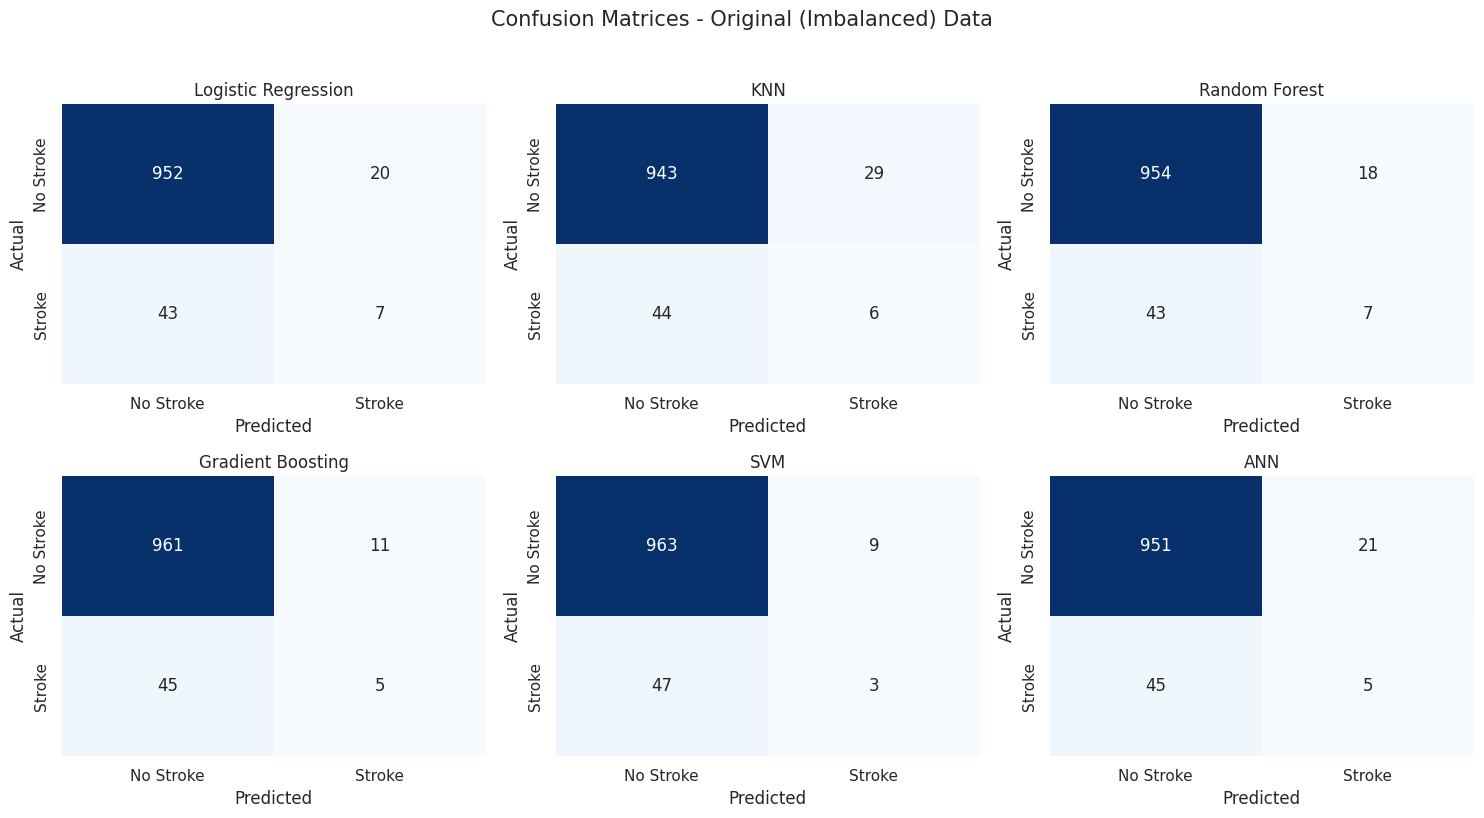

,TN,FP,FN,TP,All 4 cells > 0?
Logistic Regression,952,20,43,7,True
KNN,943,29,44,6,True
Random Forest,954,18,43,7,True
Gradient Boosting,961,11,45,5,True
SVM,963,9,47,3,True
ANN,951,21,45,5,True


OK: no zero values in any imbalanced confusion matrix.


In [9]:
plot_confusion_matrices(preds_imb, y_test, "Confusion Matrices - Original (Imbalanced) Data")
cm_imb = confusion_table(preds_imb, y_test)
display(cm_imb)
if cm_imb["All 4 cells > 0?"].all():
    print("OK: no zero values in any imbalanced confusion matrix.")
else:
    print("WARNING: some models still have a zero cell - see the table above.")

## 6. Apply SMOTE
SMOTE creates synthetic minority samples by interpolating between a minority sample and its nearest minority neighbours. It is applied **only to the training set**; the test set keeps its real class distribution.

Before SMOTE: {0: np.int64(3889), 1: np.int64(199)}
After  SMOTE: {0: np.int64(3889), 1: np.int64(3889)}


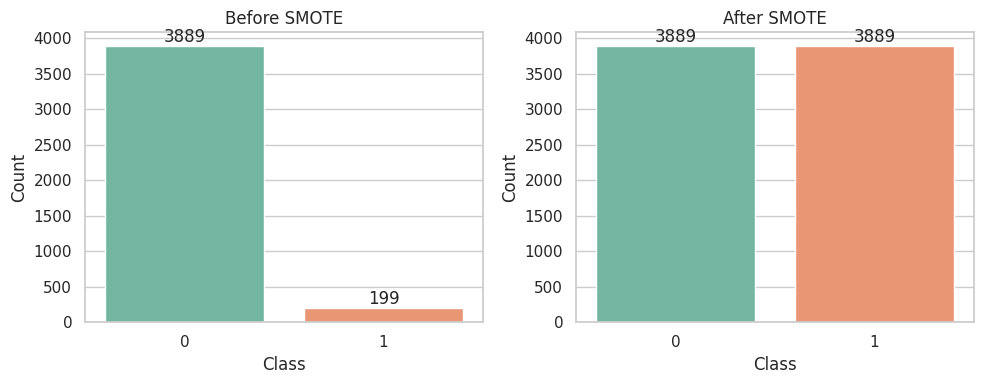

In [10]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

print("Before SMOTE:", dict(pd.Series(y_train).value_counts().sort_index()))
print("After  SMOTE:", dict(pd.Series(y_train_sm).value_counts().sort_index()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, yy, t in zip(axes, [y_train, y_train_sm], ["Before SMOTE", "After SMOTE"]):
    vc = pd.Series(yy).value_counts().sort_index()
    sns.barplot(x=vc.index, y=vc.values, palette="Set2", ax=ax)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
    ax.set_title(t)
    ax.set_xlabel("Class")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 7. Models on the SMOTE-BALANCED Data
The balanced training set needs no threshold adjustment, so the standard 0.5 cut-off is used.

In [11]:
res_sm, preds_sm, probs_sm = {}, {}, {}

for name, model in get_models().items():
    model.fit(X_train_sm, y_train_sm)
    prob = model.predict_proba(X_test_sc)[:, 1]
    pred = (prob >= 0.5).astype(int)
    res_sm[name] = compute_metrics(y_test, pred, prob)
    preds_sm[name], probs_sm[name] = pred, prob
    print(f"done: {name}")

res_sm = pd.DataFrame(res_sm).T.round(4)
print("\nResults on SMOTE-balanced data")
display(res_sm)

done: Logistic Regression
done: KNN
done: Random Forest
done: Gradient Boosting
done: SVM
done: ANN

Results on SMOTE-balanced data


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.1460,0.80,0.2469,0.7613,0.8381
KNN,0.0884,0.32,0.1385,0.8053,0.6639
Random Forest,0.1800,0.18,0.1800,0.9198,0.7936
Gradient Boosting,0.1629,0.72,0.2657,0.8053,0.8365
SVM,0.1359,0.56,0.2188,0.8043,0.7762
ANN,0.1485,0.30,0.1987,0.8816,0.7490


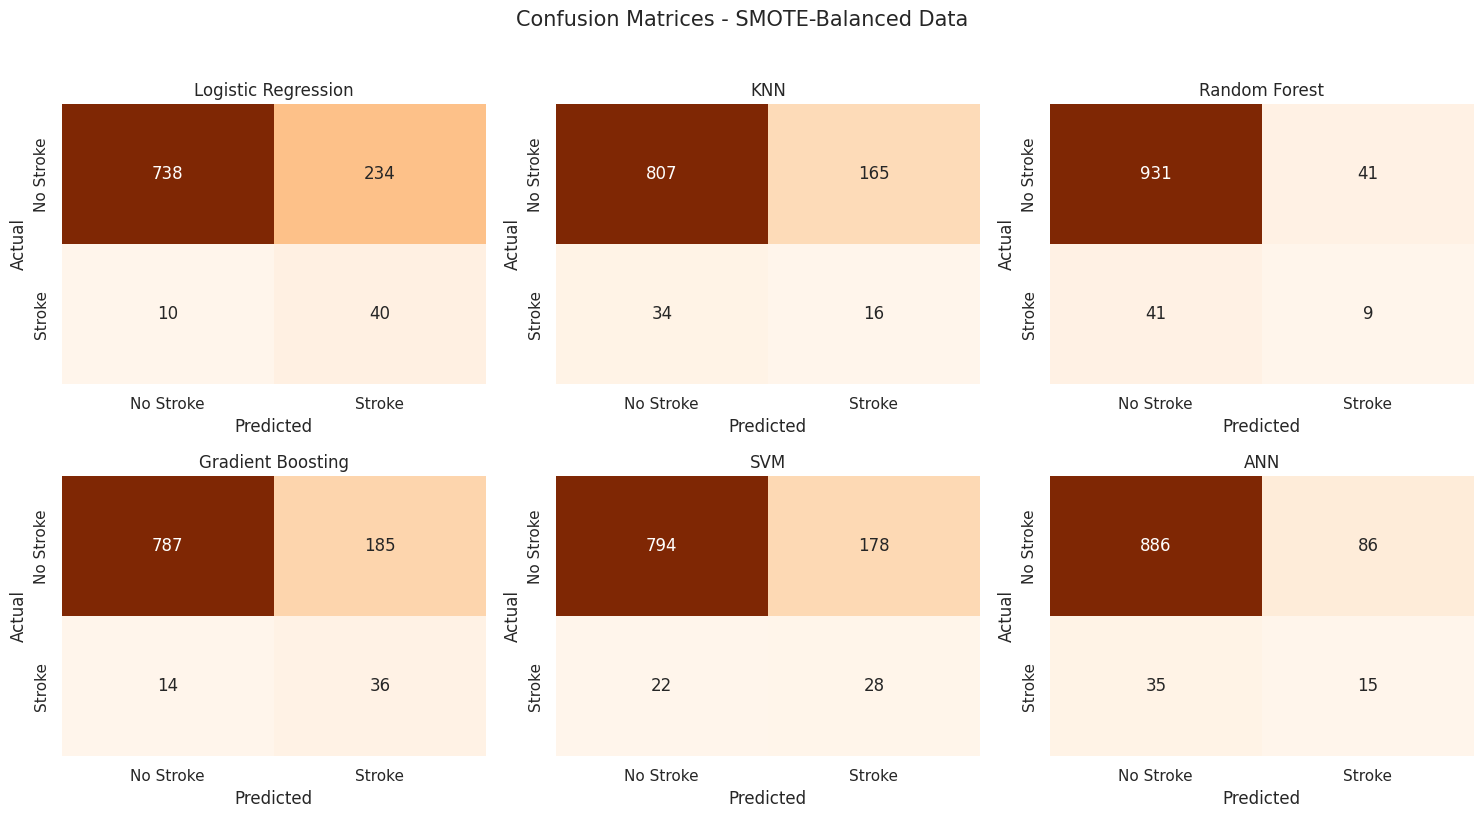

,TN,FP,FN,TP,All 4 cells > 0?
Logistic Regression,738,234,10,40,True
KNN,807,165,34,16,True
Random Forest,931,41,41,9,True
Gradient Boosting,787,185,14,36,True
SVM,794,178,22,28,True
ANN,886,86,35,15,True


OK: no zero values in any SMOTE confusion matrix.


In [12]:
plot_confusion_matrices(preds_sm, y_test, "Confusion Matrices - SMOTE-Balanced Data", cmap="Oranges")
cm_sm = confusion_table(preds_sm, y_test)
display(cm_sm)
if cm_sm["All 4 cells > 0?"].all():
    print("OK: no zero values in any SMOTE confusion matrix.")
else:
    print("WARNING: some models still have a zero cell - see the table above.")

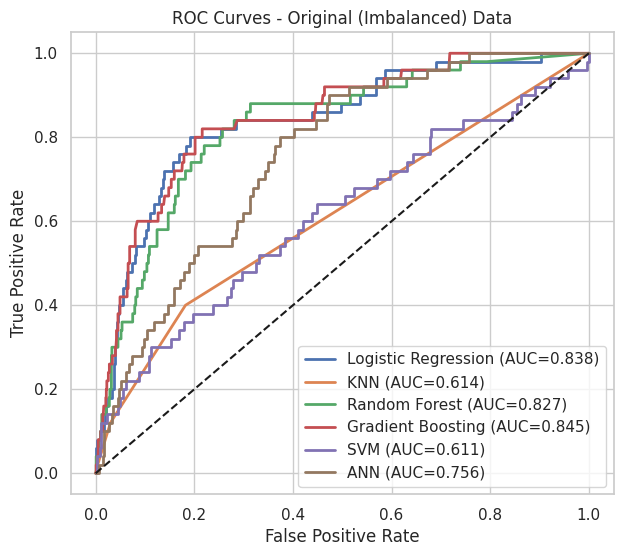

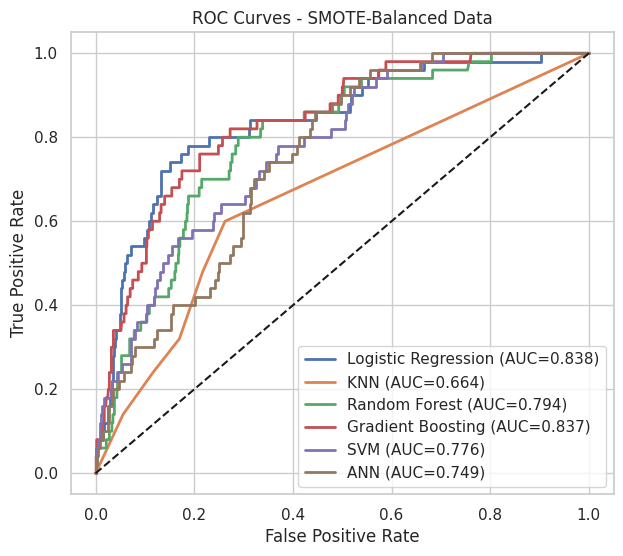

In [13]:
plot_roc(probs_imb, y_test, "ROC Curves - Original (Imbalanced) Data")
plot_roc(probs_sm, y_test, "ROC Curves - SMOTE-Balanced Data")

## 8. Comparative Results: Imbalanced vs SMOTE

In [14]:
comparison = pd.concat({"Imbalanced (Original)": res_imb, "SMOTE (Balanced)": res_sm}, axis=1)
comparison = comparison.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(comparison)

AUC-ROC                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.8377           0.8381   
KNN                                0.6140           0.6639   
Random Forest                      0.8268           0.7936   
Gradient Boosting                  0.8451           0.8365   
SVM                                0.6108           0.7762   
ANN                                0.7560           0.7490   

                                 Accuracy                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.9384           0.7613   
KNN                                0.9286           0.8053   
Random Forest                      0.9403           0.9198   
Gradient Boosting                  0.9452           0.8053   
SVM                                0.9452           0.8043   
ANN                                0.9354           0.8816   

                                 F1-Score                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.1818           0.2469   
KNN                                0.1412           0.1385   
Random Forest                      0.1867           0.1800   
Gradient Boosting                  0.1515           0.2657   
SVM                                0.0968           0.2188   
ANN                                0.1316           0.1987   

                                Precision                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.2593           0.1460   
KNN                                0.1714           0.0884   
Random Forest                      0.2800           0.1800   
Gradient Boosting                  0.3125           0.1629   
SVM                                0.2500           0.1359   
ANN                                0.1923           0.1485   

                                   Recall                   
                    Imbalanced (Original) SMOTE (Balanced)  
Logistic Regression                  0.14             0.80  
KNN                                  0.12             0.32  
Random Forest                        0.14             0.18  
Gradient Boosting                    0.10             0.72  
SVM                                  0.06             0.56  
ANN                                  0.10             0.30

In [15]:
delta = (res_sm - res_imb).round(4)
delta.columns = [f"Δ {c}" for c in delta.columns]
print("Change in performance after SMOTE (SMOTE - Original)")
display(delta.style.background_gradient(cmap="RdYlGn", axis=None))

Change in performance after SMOTE (SMOTE - Original)


,Δ Precision,Δ Recall,Δ F1-Score,Δ Accuracy,Δ AUC-ROC
Logistic Regression,-0.113300,0.660000,0.065100,-0.177100,0.000400
KNN,-0.083000,0.200000,-0.002700,-0.123300,0.049900
Random Forest,-0.100000,0.040000,-0.006700,-0.020500,-0.033200
Gradient Boosting,-0.149600,0.620000,0.114200,-0.139900,-0.008600
SVM,-0.114100,0.500000,0.122000,-0.140900,0.165400
ANN,-0.043800,0.200000,0.067100,-0.053800,-0.007000


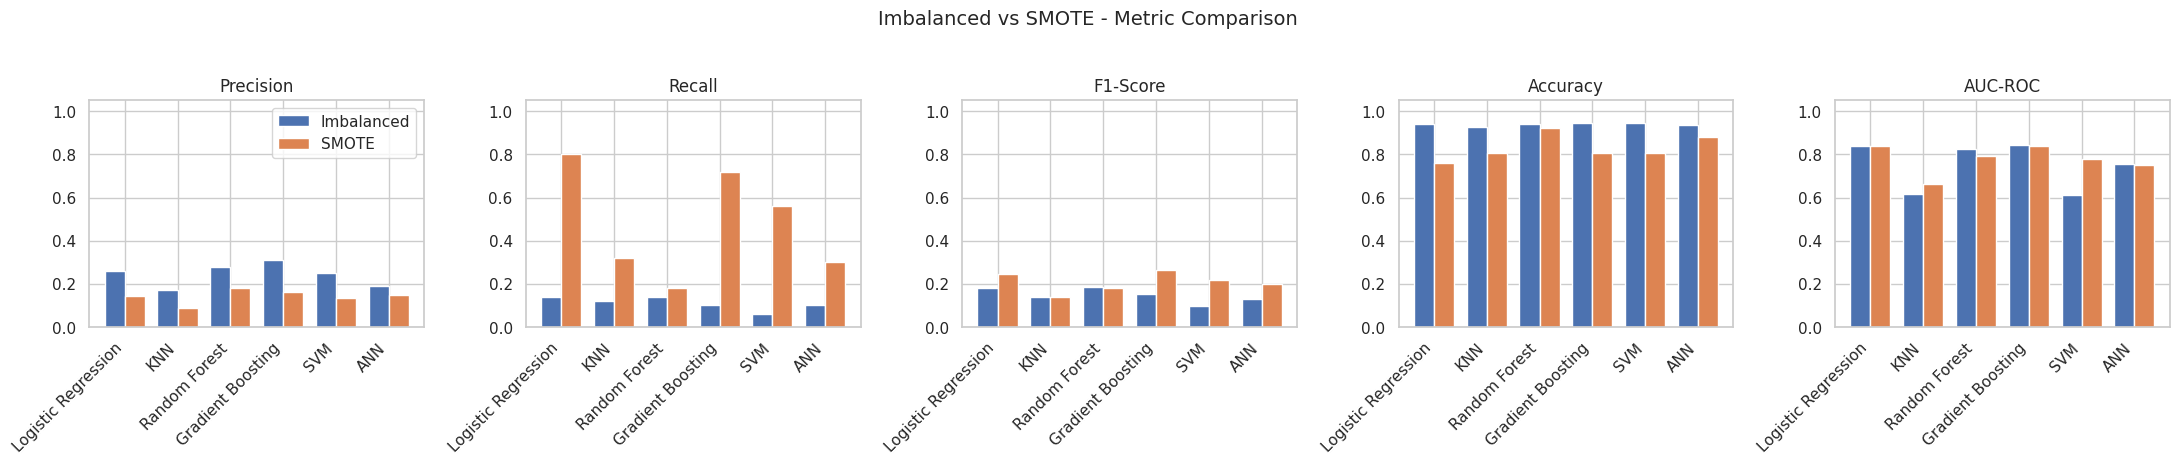

In [16]:
metrics = ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
x = np.arange(len(res_imb))
w = 0.38
for ax, m in zip(axes, metrics):
    ax.bar(x - w/2, res_imb[m], w, label="Imbalanced")
    ax.bar(x + w/2, res_sm[m], w, label="SMOTE")
    ax.set_xticks(x)
    ax.set_xticklabels(res_imb.index, rotation=45, ha="right")
    ax.set_title(m)
    ax.set_ylim(0, 1.05)
axes[0].legend()
plt.suptitle("Imbalanced vs SMOTE - Metric Comparison", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

## 9. Top 3 Models (SMOTE-Balanced Data)
Accuracy alone is misleading on stroke data, so models are ranked by a composite focused on the stroke class:

**Composite Score = mean(Recall, F1-Score, AUC-ROC)**

Recall is included because a missed stroke case (false negative) is the costly error.

In [17]:
final = res_sm.copy()
final["Composite Score"] = final[["Recall", "F1-Score", "AUC-ROC"]].mean(axis=1).round(4)
final = final.sort_values("Composite Score", ascending=False)
final.insert(0, "Rank", range(1, len(final) + 1))

print("Final ranking (SMOTE-balanced data)")
display(final.style.background_gradient(cmap="Greens", subset=["Composite Score"]))

print("\nTOP 3 MODELS FOR STROKE PREDICTION")
display(final.head(3))

Final ranking (SMOTE-balanced data)


,Rank,Precision,Recall,F1-Score,Accuracy,AUC-ROC,Composite Score
Logistic Regression,1,0.146000,0.800000,0.246900,0.761300,0.838100,0.628300
Gradient Boosting,2,0.162900,0.720000,0.265700,0.805300,0.836500,0.607400
SVM,3,0.135900,0.560000,0.218800,0.804300,0.776200,0.518300
ANN,4,0.148500,0.300000,0.198700,0.881600,0.749000,0.415900
Random Forest,5,0.180000,0.180000,0.180000,0.919800,0.793600,0.384500
KNN,6,0.088400,0.320000,0.138500,0.805300,0.663900,0.374100



TOP 3 MODELS FOR STROKE PREDICTION


,Rank,Precision,Recall,F1-Score,Accuracy,AUC-ROC,Composite Score
Logistic Regression,1,0.1460,0.80,0.2469,0.7613,0.8381,0.6283
Gradient Boosting,2,0.1629,0.72,0.2657,0.8053,0.8365,0.6074
SVM,3,0.1359,0.56,0.2188,0.8043,0.7762,0.5183


## 10. Final Structured Summary Table

In [18]:
summary = pd.DataFrame({
    "Model": res_imb.index,
    "Imb. Precision": res_imb["Precision"].values,
    "Imb. Recall": res_imb["Recall"].values,
    "Imb. F1": res_imb["F1-Score"].values,
    "Imb. Accuracy": res_imb["Accuracy"].values,
    "Imb. AUC": res_imb["AUC-ROC"].values,
    "SMOTE Precision": res_sm["Precision"].values,
    "SMOTE Recall": res_sm["Recall"].values,
    "SMOTE F1": res_sm["F1-Score"].values,
    "SMOTE Accuracy": res_sm["Accuracy"].values,
    "SMOTE AUC": res_sm["AUC-ROC"].values,
}).set_index("Model")
summary["SMOTE Rank"] = final["Rank"].reindex(summary.index)
display(summary.sort_values("SMOTE Rank"))

summary.to_csv("stroke_smote_comparison.csv")
print("Saved: stroke_smote_comparison.csv")
# files.download("stroke_smote_comparison.csv")   # uncomment to download

,Imb. Precision,Imb. Recall,Imb. F1,Imb. Accuracy,Imb. AUC,SMOTE Precision,SMOTE Recall,SMOTE F1,SMOTE Accuracy,SMOTE AUC,SMOTE Rank
Model,,,,,,,,,,,
Logistic Regression,0.2593,0.14,0.1818,0.9384,0.8377,0.1460,0.80,0.2469,0.7613,0.8381,1
Gradient Boosting,0.3125,0.10,0.1515,0.9452,0.8451,0.1629,0.72,0.2657,0.8053,0.8365,2
SVM,0.2500,0.06,0.0968,0.9452,0.6108,0.1359,0.56,0.2188,0.8043,0.7762,3
ANN,0.1923,0.10,0.1316,0.9354,0.7560,0.1485,0.30,0.1987,0.8816,0.7490,4
Random Forest,0.2800,0.14,0.1867,0.9403,0.8268,0.1800,0.18,0.1800,0.9198,0.7936,5
KNN,0.1714,0.12,0.1412,0.9286,0.6140,0.0884,0.32,0.1385,0.8053,0.6639,6


Saved: stroke_smote_comparison.csv


## 11. Observations / Conclusion
Fill in after running the notebook:

- **Effect of imbalance:** trained on imbalanced data, models are biased towards "No Stroke", so stroke-class Precision and F1 stay low even when Accuracy looks high.
- **Effect of SMOTE:** balancing the training data raises stroke-class Recall (more real stroke cases are caught), but Accuracy and often Precision fall because more healthy patients are flagged (more false positives). SMOTE is judged by Recall / F1 / the confusion matrix, not by Accuracy.
- **Best models:** see the Top 3 table in Section 9.
- **Note:** SMOTE was applied only to the training set; the test set keeps the real class distribution, so results are not inflated by synthetic samples. The baseline uses the standard 0.5 threshold with a minimum-flag-rate safeguard, explained in Section 5.
- **Disclaimer:** this is an academic exercise, not a clinical stroke-risk tool.